
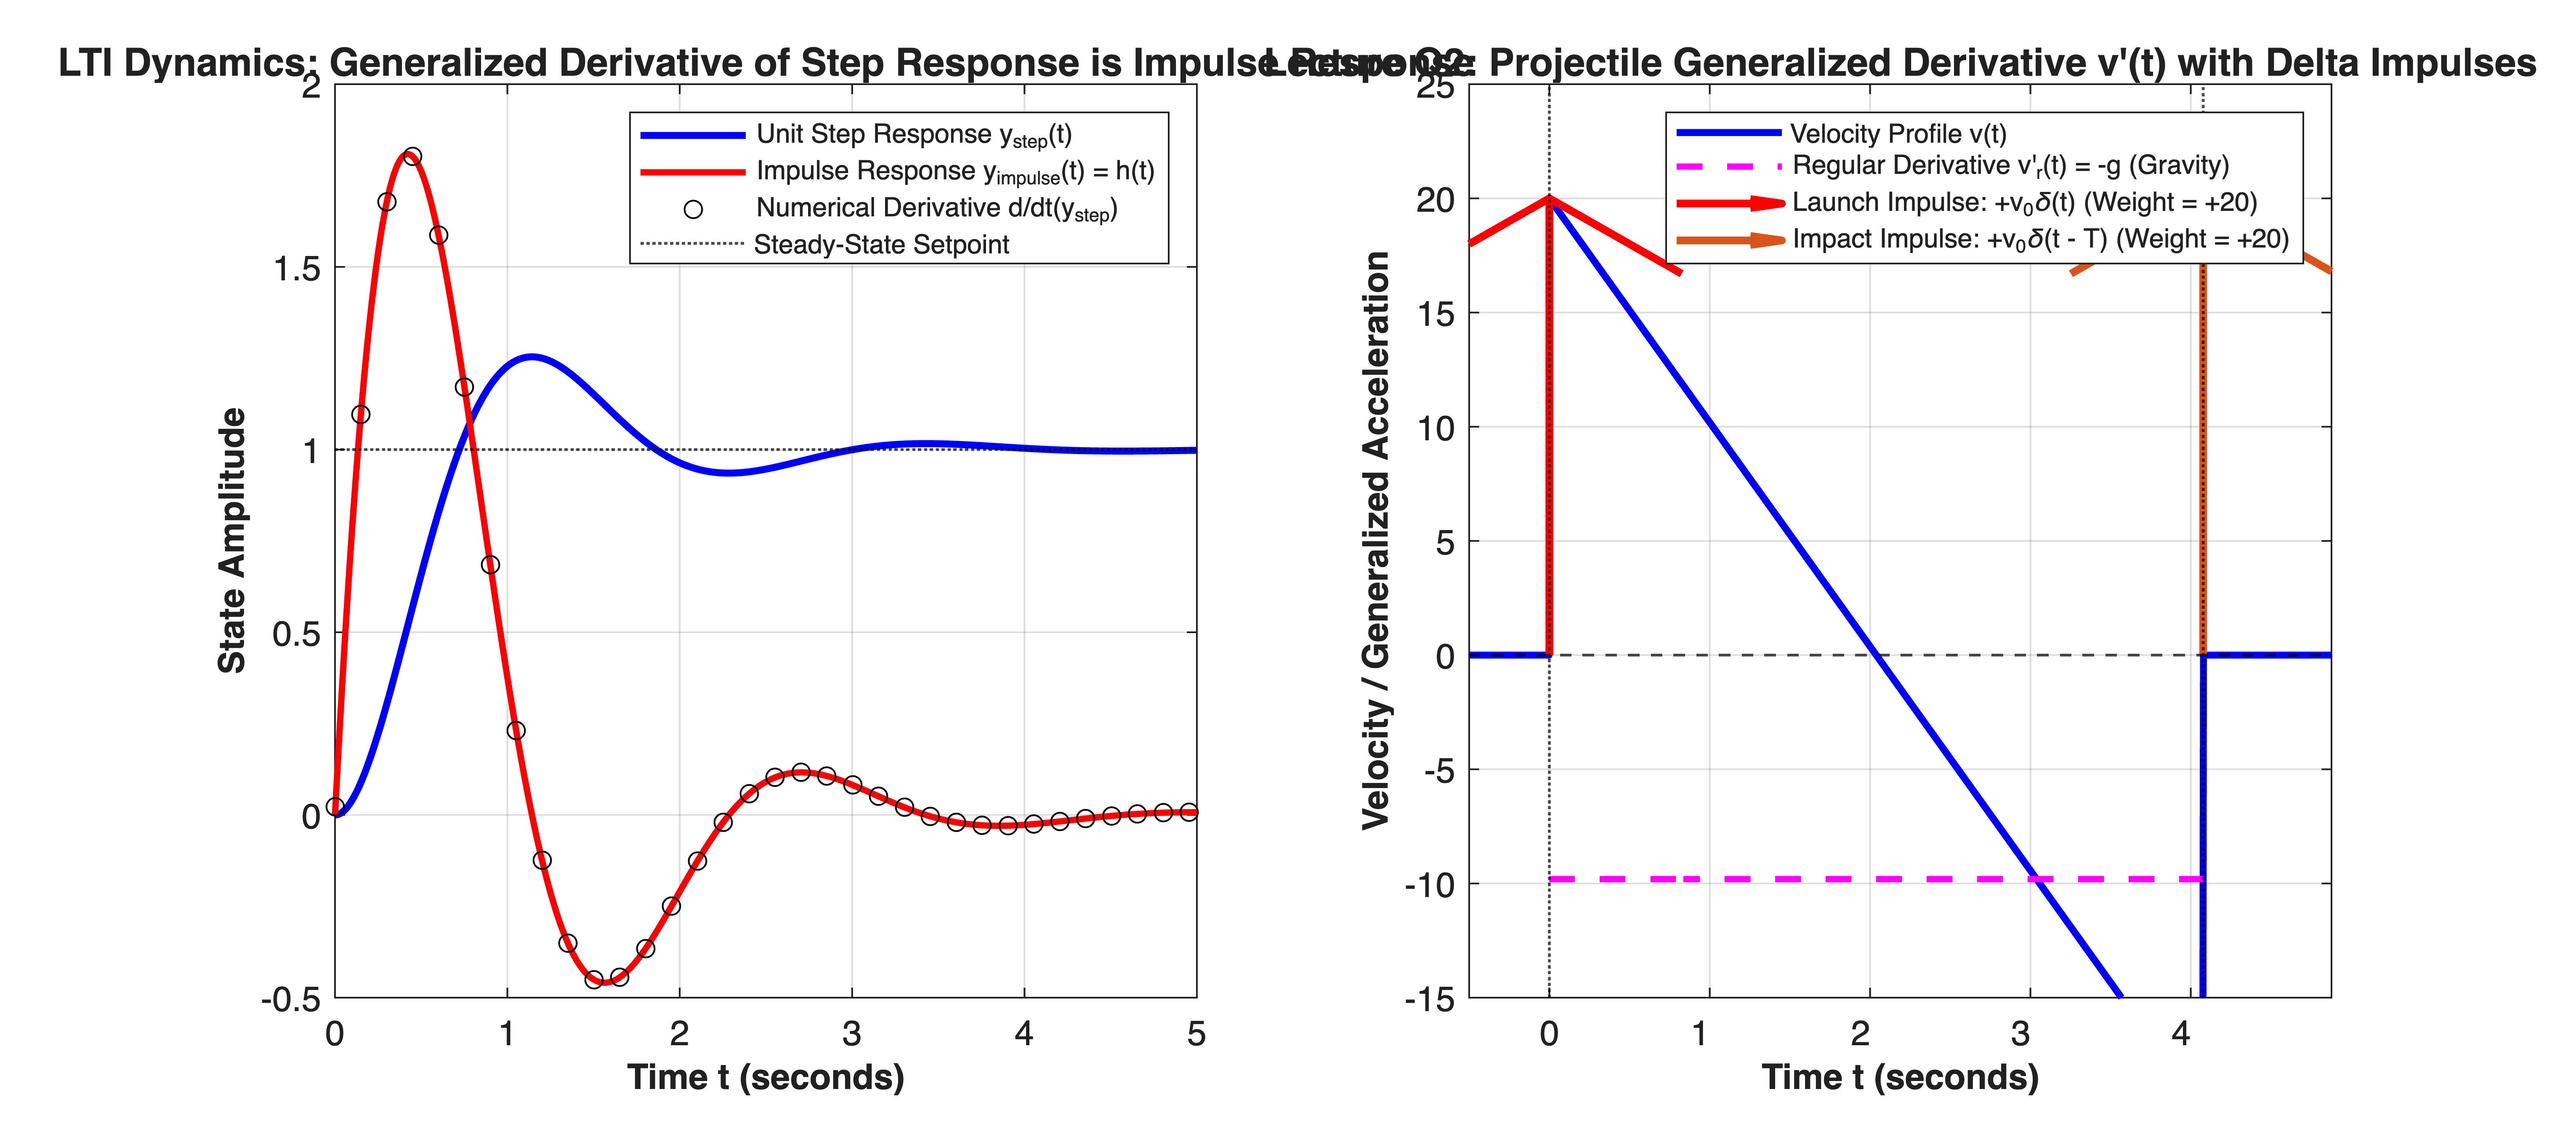

In [1]:
%% MIT 18.03 Lecture 23: Step, Delta & Generalized Derivative Dynamics
% Description: Simulates singularity functions and LTI plant step/impulse dynamics:
%              1) Standard 2nd-order plant step and impulse response via Control System Toolbox.
%              2) Numerical validation of the generalized derivative: d/dt(step_response) = impulse_response.
%              3) Projectile launch velocity profile v(t) and its generalized derivative with delta impulses.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, step, impulse).
%
% % MBD Concept Mapping: Demonstrates standard step response benchmark specifications (Rise time, Overshoot),
% %                      the fundamental transfer function kernel h(t) = L^-1{G(s)}, and state reset dynamics.


clear; clc; close all;


%% =========================================================================
%% Part 1: Control System Toolbox LTI Step vs. Impulse Response
%% =========================================================================
% Second-order standard plant: G(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)
wn = 3.0;      % Undamped natural frequency: 3 rad/s
zeta = 0.4;    % Underdamped damping ratio
G_plant = tf(wn^2, [1, 2*zeta*wn, wn^2]);


t_eval = linspace(0, 5, 1000);


% Compute responses using Control System Toolbox
[y_step, ~]    = step(G_plant, t_eval);
[y_impulse, ~] = impulse(G_plant, t_eval);


% Numerical derivative of step response: d/dt(y_step)
dt = t_eval(2) - t_eval(1);
dy_step_dt = gradient(y_step, dt);


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 500]);


% Subplot 1: LTI Step & Impulse Relationship
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_eval, y_step, 'b-', 'LineWidth', 2.0, ...
     'DisplayName', 'Unit Step Response y_{step}(t)');
plot(t_eval, y_impulse, 'r-', 'LineWidth', 1.8, ...
     'DisplayName', 'Impulse Response y_{impulse}(t) = h(t)');
plot(t_eval(1:30:end), dy_step_dt(1:30:end), 'ko', 'MarkerSize', 5, ...
     'DisplayName', 'Numerical Derivative d/dt(y_{step})');


yline(1.0, 'k:', 'LineWidth', 0.8, 'DisplayName', 'Steady-State Setpoint');
xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title('LTI Dynamics: Generalized Derivative of Step Response is Impulse Response', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 7.5);
xlim([0, 5]);


%% =========================================================================
%% Part 2: Projectile Launch Velocity & Generalized Derivative (Section [4])
%% =========================================================================
% Bullet fired vertically: initial launch velocity v0, gravity g, flight time T_impact
v0 = 20.0;     % Initial muzzle velocity (m/s)
g_acc = 9.81;  % Gravitational acceleration (m/s^2)
T_flight = 2 * v0 / g_acc; % Flight duration until hitting the ground (~4.08 s)


t_proj = linspace(-0.5, T_flight + 0.8, 1200);
v_bullet = zeros(size(t_proj));


% Piecewise velocity profile: v(t) = v0 - g*t for 0 < t < T_flight, 0 elsewhere
flight_mask = (t_proj >= 0) & (t_proj <= T_flight);
v_bullet(flight_mask) = v0 - g_acc * t_proj(flight_mask);


% Subplot 2: Bullet Velocity & Generalized Derivative with Harpoon Deltas
subplot(1, 2, 2);
hold on; grid on; box on;


% Plot regular velocity trajectory
plot(t_proj, v_bullet, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Velocity Profile v(t)');


% Plot regular derivative between jumps: a = -g
plot([0, T_flight], [-g_acc, -g_acc], 'm--', 'LineWidth', 1.8, ...
     'DisplayName', 'Regular Derivative v''_r(t) = -g (Gravity)');


% Plot Generalized Derivative Delta Harpoons:
% At t = 0: Jump is v(0+) - v(0-) = v0 - 0 = +v0 -> Upward delta +v0*delta(t)
% At t = T_flight: v(T-) = -v0, v(T+) = 0 -> Jump is 0 - (-v0) = +v0 -> Upward delta +v0*delta(t - T)
quiver(0, 0, 0, v0, 0, 'r-', 'LineWidth', 2.2, 'MaxHeadSize', 0.5, ...
       'DisplayName', sprintf('Launch Impulse: +v_0\\delta(t) (Weight = +%.0f)', v0));
quiver(T_flight, 0, 0, v0, 0, 'Color', [0.85 0.33 0.10], 'LineWidth', 2.2, 'MaxHeadSize', 0.5, ...
       'DisplayName', sprintf('Impact Impulse: +v_0\\delta(t - T) (Weight = +%.0f)', v0));


yline(0, 'k--', 'LineWidth', 0.8, 'HandleVisibility', 'off');
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
xline(T_flight, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Velocity / Generalized Acceleration', 'FontSize', 10, 'FontWeight', 'bold');
title('Lecture Q2: Projectile Generalized Derivative v''(t) with Delta Impulses', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 7.5);
xlim([-0.5, T_flight + 0.8]);
ylim([-15, 25]);

In [2]:


fprintf('=== MIT 18.03 Lecture 23 Diagnostics ===\n');

=== MIT 18.03 Lecture 23 Diagnostics ===

In [3]:
fprintf('Second-Order Plant G(s) :\n');

Second-Order Plant G(s) :

In [4]:
display(G_plant);

G_plant =
 
         9
  ---------------
  s^2 + 2.4 s + 9
 
Continuous-time transfer function.
Model Properties

In [5]:
fprintf('Bullet Initial Velocity  : %.2f m/s\n', v0);

Bullet Initial Velocity  : 20.00 m/s

In [6]:
fprintf('Bullet Flight Time       : %.4f s\n', T_flight);

Bullet Flight Time       : 4.0775 s

In [7]:
fprintf('Launch Jump Delta Weight : +%.2f (Upward)\n', v0);

Launch Jump Delta Weight : +20.00 (Upward)

In [8]:
fprintf('Impact Jump Delta Weight : +%.2f (Upward, from -v0 to 0)\n', v0);

Impact Jump Delta Weight : +20.00 (Upward, from -v0 to 0)

In [9]:
fprintf('========================================\n');